# 🩺 Breast Cancer Classification

An end-to-end machine learning classification project that predicts whether a breast tumor is benign or malignant using diagnostic features derived from breast cancer cell measurements.

This project is built as a hands-on ML practice project to strengthen the complete machine learning workflow — from understanding the dataset and defining the problem to feature analysis, preprocessing, model evaluation, and model serialization.

## 1. Dataset & Problem Definition

The Breast Cancer Wisconsin (Diagnostic) dataset contains diagnostic measurements computed from digitized images of breast mass cell nuclei.

The goal of this project is to build a binary classification model that predicts whether a tumor is **benign (B)** or **malignant (M)** based on the available diagnostic features.

### Problem Type

This is a **binary classification** problem.

- **Input:** 30 numerical diagnostic features
- **Target:** `diagnosis`
- **Classes:** Benign (`B`) and Malignant (`M`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

In [2]:
df = pd.read_csv("../data/raw/data.csv")

## 2. Dataset Overview

The dataset contains diagnostic measurements derived from digitized images of breast mass cell nuclei. It includes 569 observations, 30 numerical diagnostic features, the `diagnosis` target, and identifier-related columns.

The initial dataset inspection is used to understand its structure, data types, missing values, duplicate records, and target distribution before moving into exploratory analysis.

In [3]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.sample(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
464,911320502,B,13.17,18.22,84.28,537.3,0.07466,0.05994,0.048590,0.028700,...,23.89,95.10,687.6,0.12820,0.19650,0.18760,0.10450,0.2235,0.06925,NaN
300,892438,M,19.53,18.90,129.50,1217.0,0.11500,0.16420,0.219700,0.106200,...,26.24,171.10,2053.0,0.14950,0.41160,0.61210,0.19800,0.2968,0.09929,NaN
257,886776,M,15.32,17.27,103.20,713.3,0.13350,0.22840,0.244800,0.124200,...,22.66,119.80,928.8,0.17650,0.45030,0.44290,0.22290,0.3258,0.11910,NaN
251,88518501,B,11.50,18.45,73.28,407.4,0.09345,0.05991,0.026380,0.020690,...,22.46,83.12,508.9,0.11830,0.10490,0.08105,0.06544,0.2740,0.06487,NaN
111,86408,B,12.63,20.76,82.15,480.4,0.09933,0.12090,0.106500,0.060210,...,25.47,89.00,527.4,0.12870,0.22500,0.22160,0.11050,0.2226,0.08486,NaN
522,91789,B,11.26,19.83,71.30,388.1,0.08511,0.04413,0.005067,0.005664,...,26.43,76.38,435.9,0.11080,0.07723,0.02533,0.02832,0.2557,0.07613,NaN
286,8912909,B,11.94,20.76,77.87,441.0,0.08605,0.10110,0.065740,0.037910,...,27.29,92.20,546.1,0.11160,0.28130,0.23650,0.11550,0.2465,0.09981,NaN
56,857637,M,19.21,18.57,125.50,1152.0,0.10530,0.12670,0.132300,0.089940,...,28.14,170.10,2145.0,0.16240,0.35110,0.38790,0.20910,0.3537,0.08294,NaN
325,89511502,B,12.67,17.30,81.25,489.9,0.10280,0.07664,0.031930,0.021070,...,21.10,88.70,574.4,0.13840,0.12120,0.10200,0.05602,0.2688,0.06888,NaN
382,90250,B,12.05,22.72,78.75,447.8,0.06935,0.10730,0.079430,0.029780,...,28.71,87.36,488.4,0.08799,0.32140,0.29120,0.10920,0.2191,0.09349,NaN


In [5]:
df.shape

(569, 33)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [7]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [8]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [9]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [10]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [11]:
df.isnull().sum().sum()

np.int64(569)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.drop(columns=["Unnamed: 32", "id"])

In [14]:
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [15]:
df["diagnosis"].describe()

count     569
unique      2
top         B
freq      357
Name: diagnosis, dtype: object

In [16]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='diagnosis'>

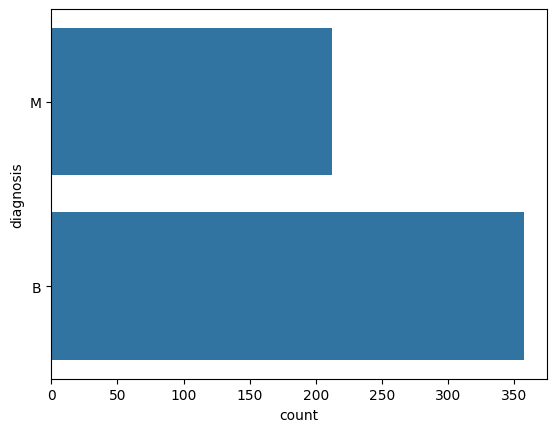

In [17]:
sns.countplot(df["diagnosis"])

In [18]:
df["diagnosis_encoded"] = df["diagnosis"].map({"B": 0, "M": 1})

## 3. Exploratory Data Analysis

Exploratory data analysis is used to understand how the diagnostic features are distributed and how their values differ between benign and malignant tumors.

The analysis is performed across the 30 numerical features, grouped by their underlying characteristics: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension.

### 3.1 Radius

In [19]:
df["radius_mean"].describe()

count    569.000000
mean      14.127292
std        3.524049
min        6.981000
25%       11.700000
50%       13.370000
75%       15.780000
max       28.110000
Name: radius_mean, dtype: float64

<Axes: xlabel='radius_mean', ylabel='Count'>

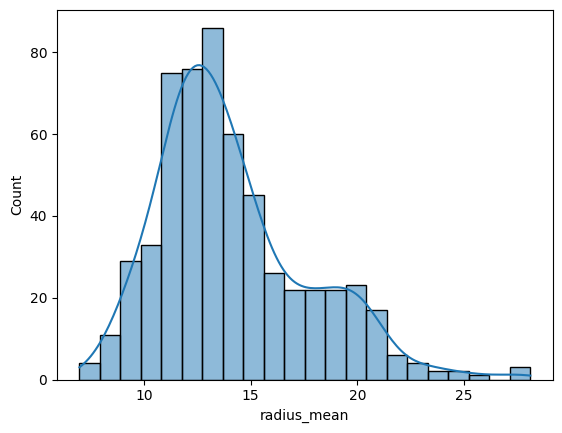

In [20]:
sns.histplot(df["radius_mean"], kde=True)

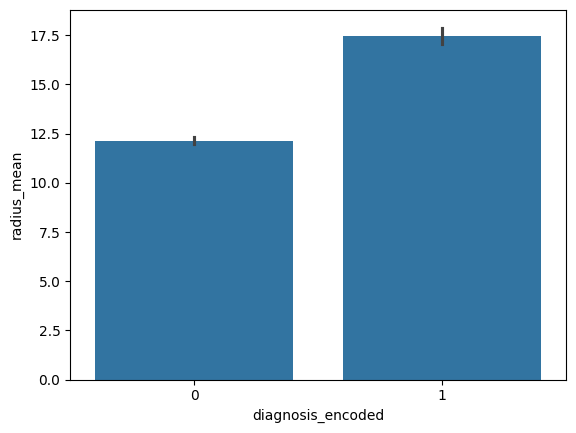

In [21]:
sns.barplot(x="diagnosis_encoded", y="radius_mean", data=df)
plt.show()

In [22]:
df["radius_se"].describe()

count    569.000000
mean       0.405172
std        0.277313
min        0.111500
25%        0.232400
50%        0.324200
75%        0.478900
max        2.873000
Name: radius_se, dtype: float64

<Axes: xlabel='radius_se', ylabel='Count'>

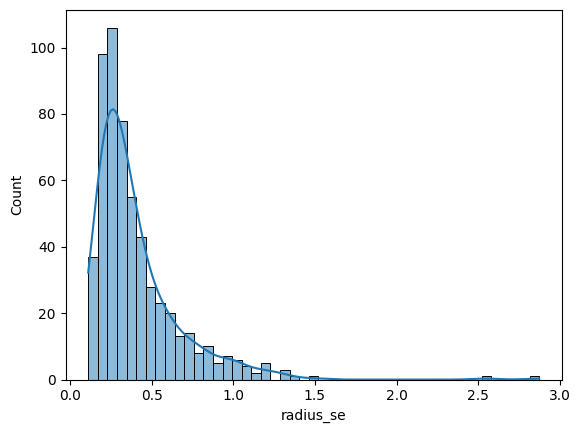

In [23]:
sns.histplot(df["radius_se"], kde=True)

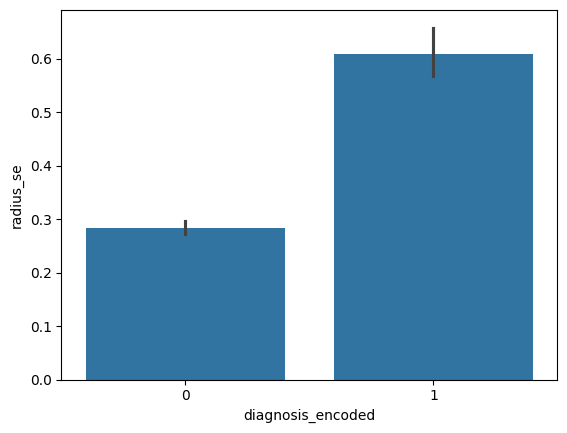

In [24]:
sns.barplot(x="diagnosis_encoded", y="radius_se", data=df)
plt.show()

In [25]:
df["radius_worst"].describe()

count    569.000000
mean      16.269190
std        4.833242
min        7.930000
25%       13.010000
50%       14.970000
75%       18.790000
max       36.040000
Name: radius_worst, dtype: float64

<Axes: xlabel='radius_worst', ylabel='Count'>

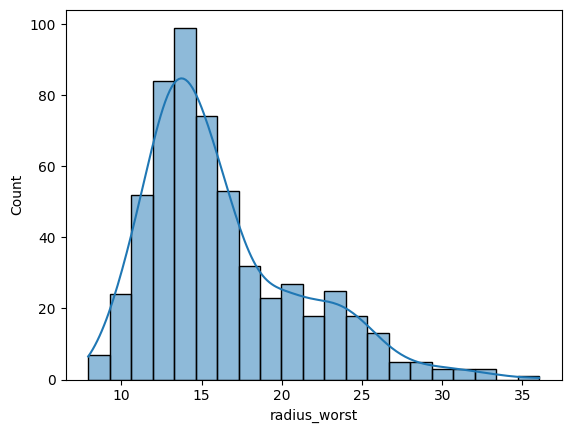

In [26]:
sns.histplot(df["radius_worst"], kde=True)

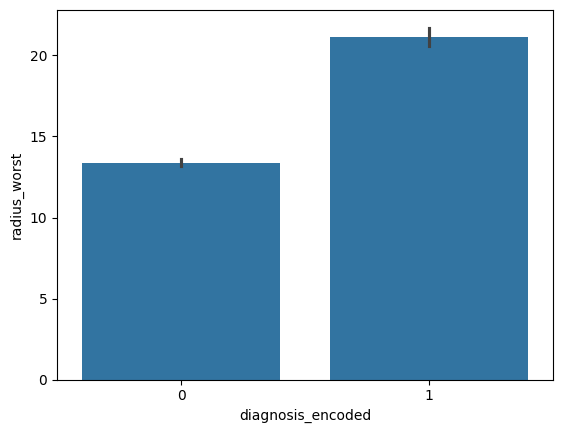

In [27]:
sns.barplot(x="diagnosis_encoded", y="radius_worst", data=df)
plt.show()

### 3.2 Texture

In [28]:
df["texture_mean"].describe()

count    569.000000
mean      19.289649
std        4.301036
min        9.710000
25%       16.170000
50%       18.840000
75%       21.800000
max       39.280000
Name: texture_mean, dtype: float64

<Axes: xlabel='texture_mean', ylabel='Count'>

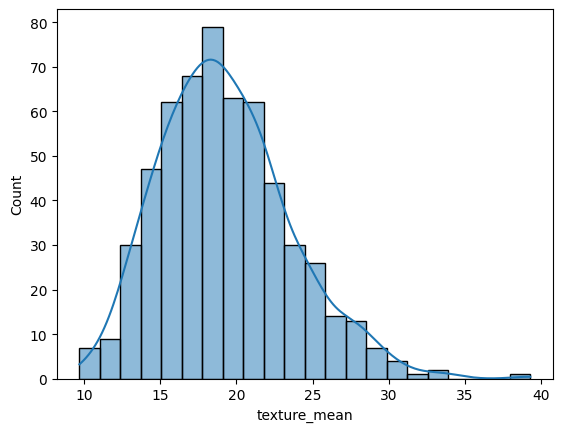

In [29]:
sns.histplot(df["texture_mean"], kde=True)

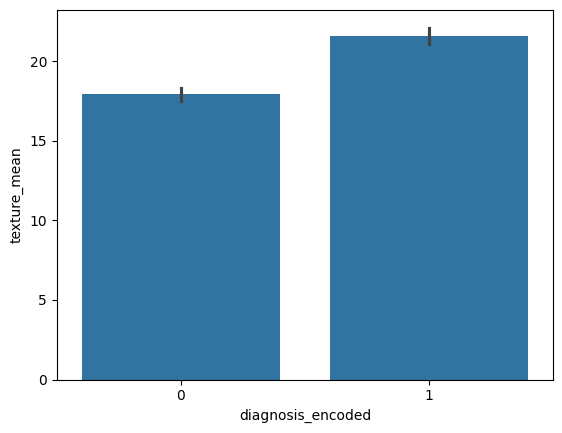

In [30]:
sns.barplot(x="diagnosis_encoded", y="texture_mean", data=df)
plt.show()

In [31]:
df["texture_se"].describe()

count    569.000000
mean       1.216853
std        0.551648
min        0.360200
25%        0.833900
50%        1.108000
75%        1.474000
max        4.885000
Name: texture_se, dtype: float64

<Axes: xlabel='texture_se', ylabel='Count'>

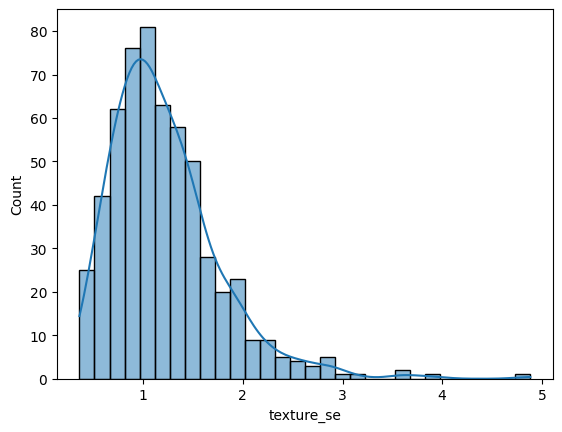

In [32]:
sns.histplot(df["texture_se"], kde=True)

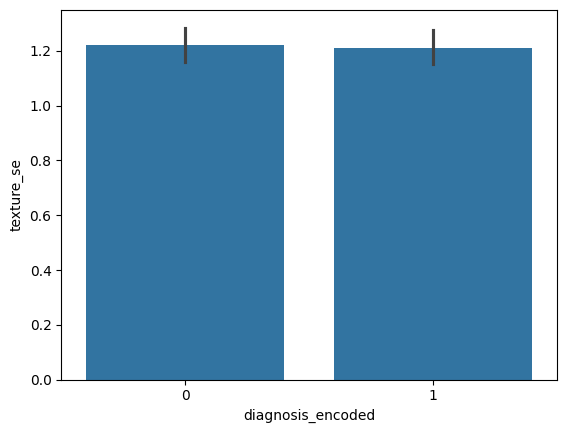

In [33]:
sns.barplot(x="diagnosis_encoded", y="texture_se", data=df)
plt.show()

In [34]:
df["texture_worst"].describe()

count    569.000000
mean      25.677223
std        6.146258
min       12.020000
25%       21.080000
50%       25.410000
75%       29.720000
max       49.540000
Name: texture_worst, dtype: float64

<Axes: xlabel='texture_worst', ylabel='Count'>

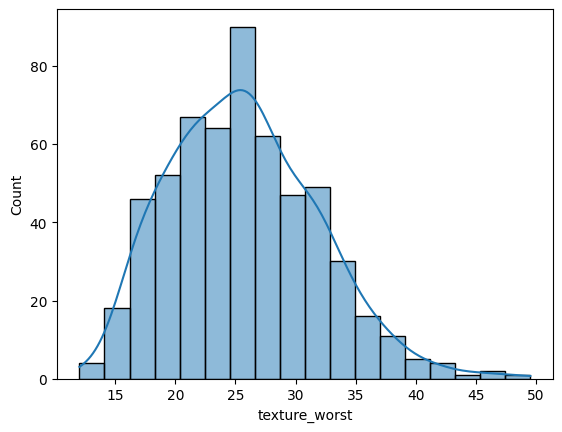

In [35]:
sns.histplot(df["texture_worst"], kde=True)

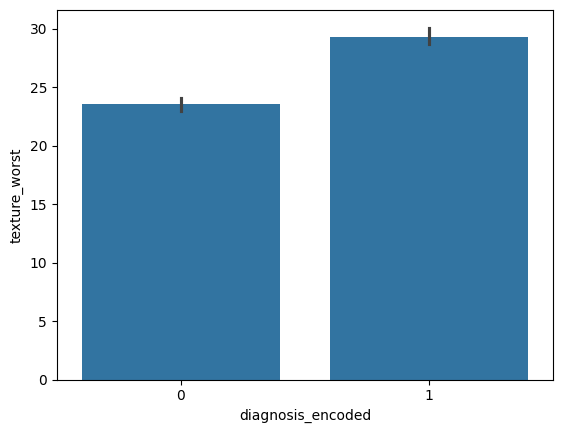

In [36]:
sns.barplot(x="diagnosis_encoded", y="texture_worst", data=df)
plt.show()

### 3.3 Perimeter

In [37]:
df["perimeter_mean"].describe()

count    569.000000
mean      91.969033
std       24.298981
min       43.790000
25%       75.170000
50%       86.240000
75%      104.100000
max      188.500000
Name: perimeter_mean, dtype: float64

<Axes: xlabel='perimeter_mean', ylabel='Count'>

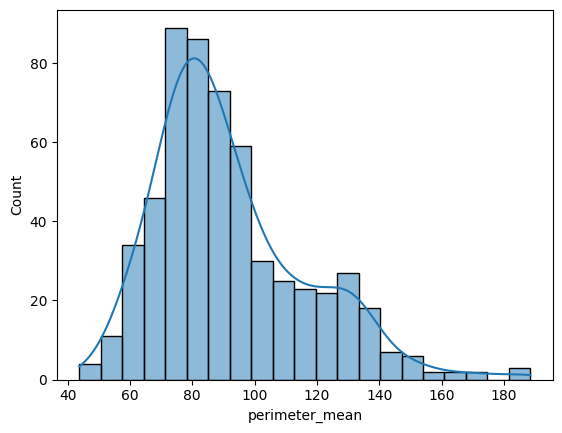

In [38]:
sns.histplot(df["perimeter_mean"], kde=True)

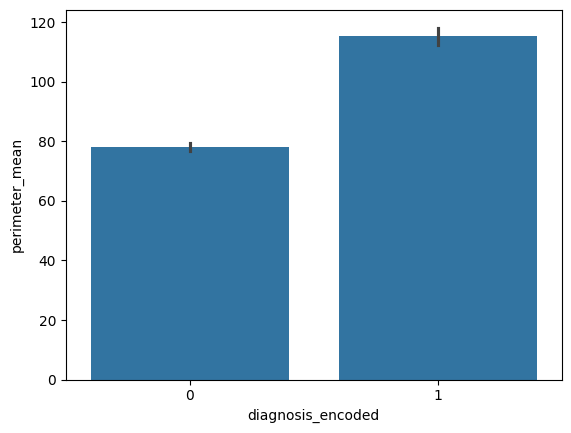

In [39]:
sns.barplot(x="diagnosis_encoded", y="perimeter_mean", data=df)
plt.show()

In [40]:
df["perimeter_se"].describe()

count    569.000000
mean       2.866059
std        2.021855
min        0.757000
25%        1.606000
50%        2.287000
75%        3.357000
max       21.980000
Name: perimeter_se, dtype: float64

<Axes: xlabel='perimeter_se', ylabel='Count'>

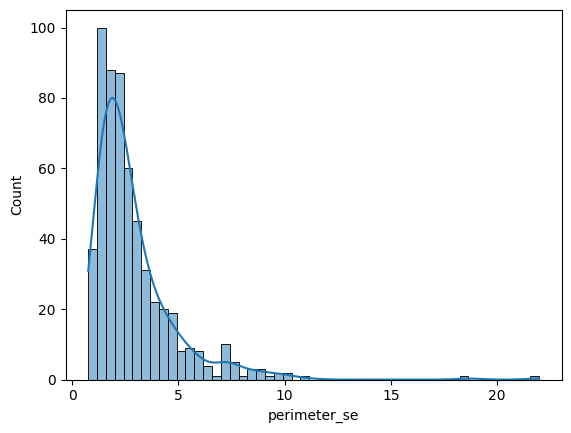

In [41]:
sns.histplot(df["perimeter_se"], kde=True)

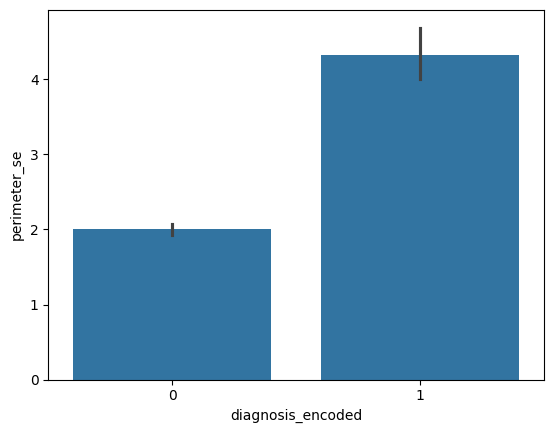

In [42]:
sns.barplot(x="diagnosis_encoded", y="perimeter_se", data=df)
plt.show()

In [43]:
df["perimeter_worst"].describe()

count    569.000000
mean     107.261213
std       33.602542
min       50.410000
25%       84.110000
50%       97.660000
75%      125.400000
max      251.200000
Name: perimeter_worst, dtype: float64

<Axes: xlabel='perimeter_worst', ylabel='Count'>

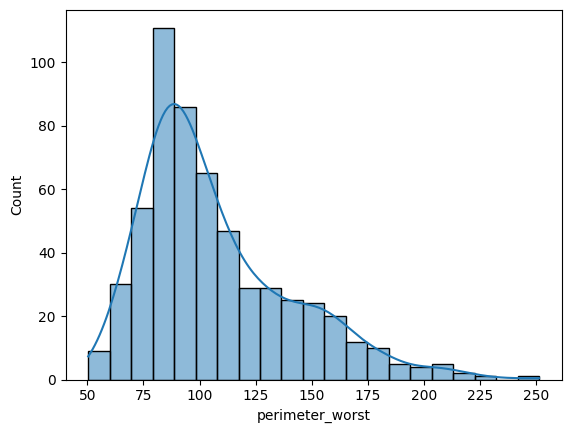

In [44]:
sns.histplot(df["perimeter_worst"], kde=True)

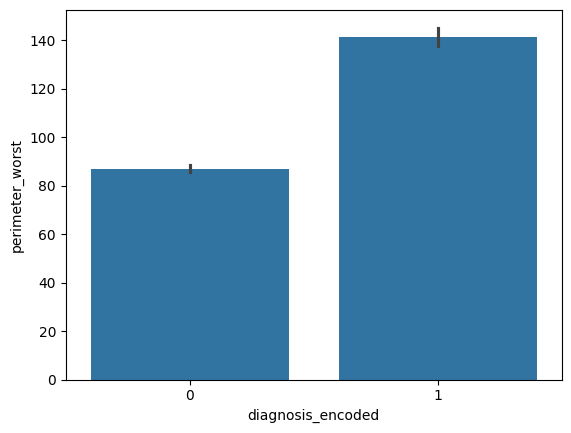

In [45]:
sns.barplot(x="diagnosis_encoded", y="perimeter_worst", data=df)
plt.show()

### 3.4 Area

In [46]:
df["area_mean"].describe()

count     569.000000
mean      654.889104
std       351.914129
min       143.500000
25%       420.300000
50%       551.100000
75%       782.700000
max      2501.000000
Name: area_mean, dtype: float64

<Axes: xlabel='area_mean', ylabel='Count'>

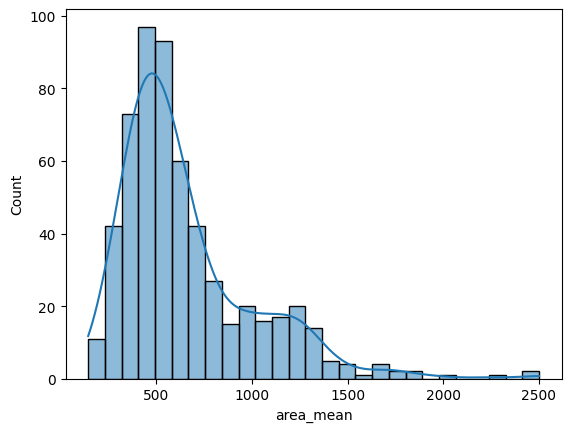

In [47]:
sns.histplot(df["area_mean"], kde=True)

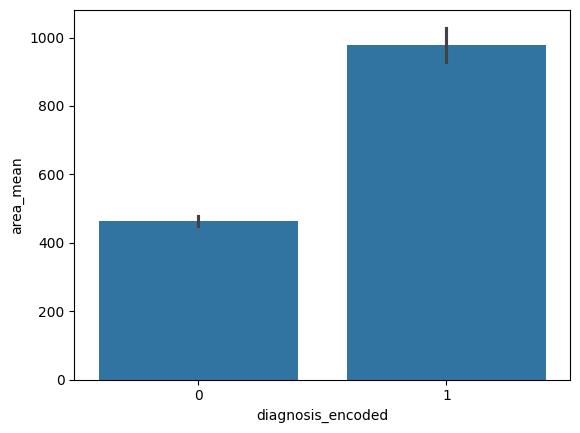

In [48]:
sns.barplot(x="diagnosis_encoded", y="area_mean", data=df)
plt.show()

In [49]:
df["area_se"].describe()

count    569.000000
mean      40.337079
std       45.491006
min        6.802000
25%       17.850000
50%       24.530000
75%       45.190000
max      542.200000
Name: area_se, dtype: float64

<Axes: xlabel='area_se', ylabel='Count'>

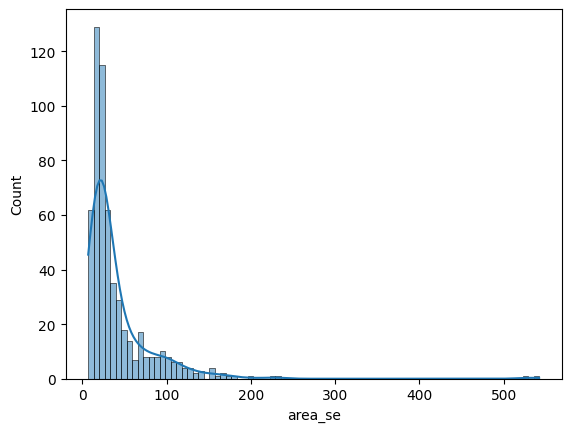

In [50]:
sns.histplot(df["area_se"], kde=True)

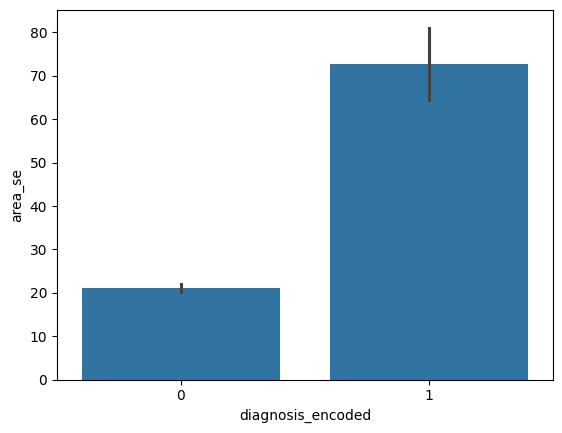

In [51]:
sns.barplot(x="diagnosis_encoded", y="area_se", data=df)
plt.show()

In [52]:
df["area_worst"].describe()

count     569.000000
mean      880.583128
std       569.356993
min       185.200000
25%       515.300000
50%       686.500000
75%      1084.000000
max      4254.000000
Name: area_worst, dtype: float64

<Axes: xlabel='area_worst', ylabel='Count'>

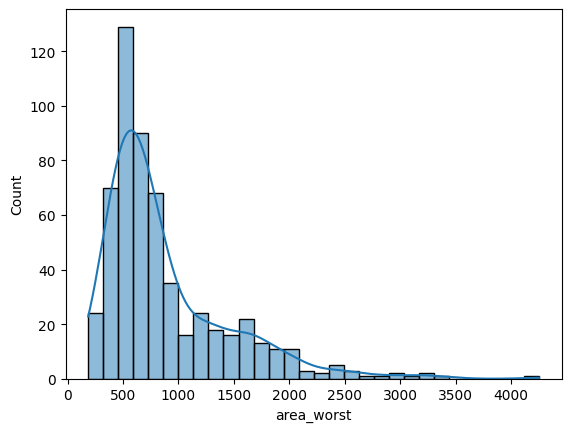

In [53]:
sns.histplot(df["area_worst"], kde=True)

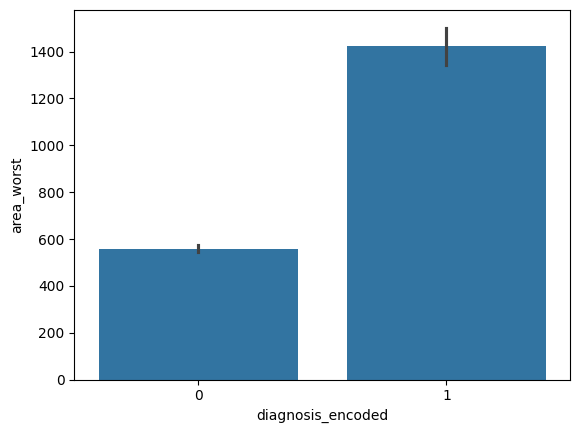

In [54]:
sns.barplot(x="diagnosis_encoded", y="area_worst", data=df)
plt.show()

### 3.5 Smoothness

In [55]:
df["smoothness_mean"].describe()

count    569.000000
mean       0.096360
std        0.014064
min        0.052630
25%        0.086370
50%        0.095870
75%        0.105300
max        0.163400
Name: smoothness_mean, dtype: float64

<Axes: xlabel='smoothness_mean', ylabel='Count'>

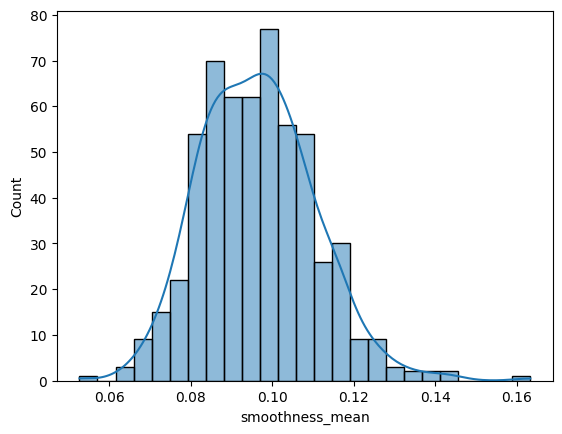

In [56]:
sns.histplot(df["smoothness_mean"], kde=True)

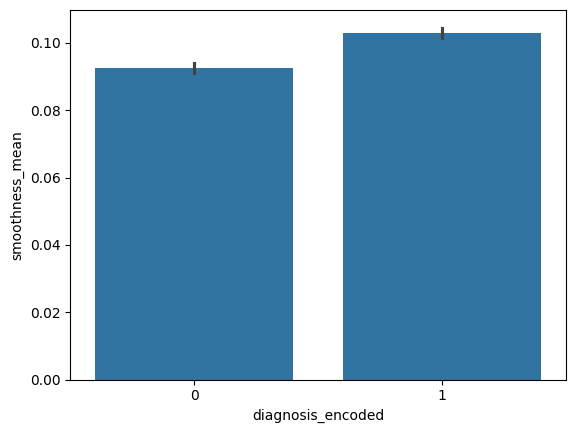

In [57]:
sns.barplot(x="diagnosis_encoded", y="smoothness_mean", data=df)
plt.show()

In [58]:
df["smoothness_se"].describe()

count    569.000000
mean       0.007041
std        0.003003
min        0.001713
25%        0.005169
50%        0.006380
75%        0.008146
max        0.031130
Name: smoothness_se, dtype: float64

<Axes: xlabel='smoothness_se', ylabel='Count'>

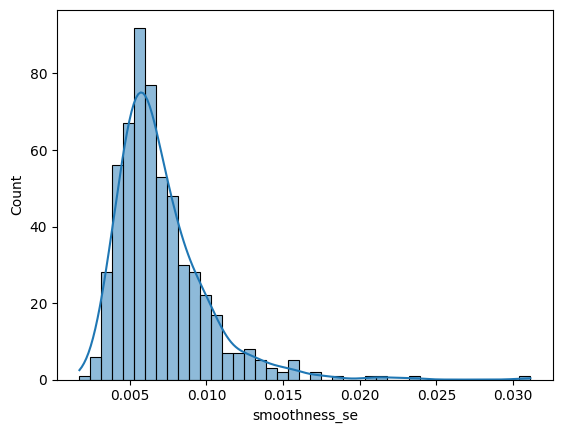

In [59]:
sns.histplot(df["smoothness_se"], kde=True)

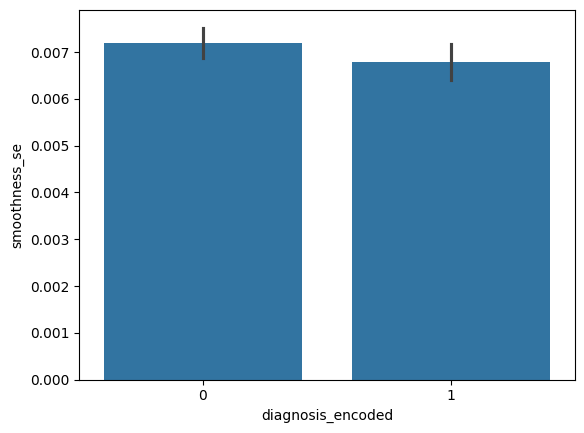

In [60]:
sns.barplot(x="diagnosis_encoded", y="smoothness_se", data=df)
plt.show()

In [61]:
df["smoothness_worst"].describe()

count    569.000000
mean       0.132369
std        0.022832
min        0.071170
25%        0.116600
50%        0.131300
75%        0.146000
max        0.222600
Name: smoothness_worst, dtype: float64

<Axes: xlabel='smoothness_worst', ylabel='Count'>

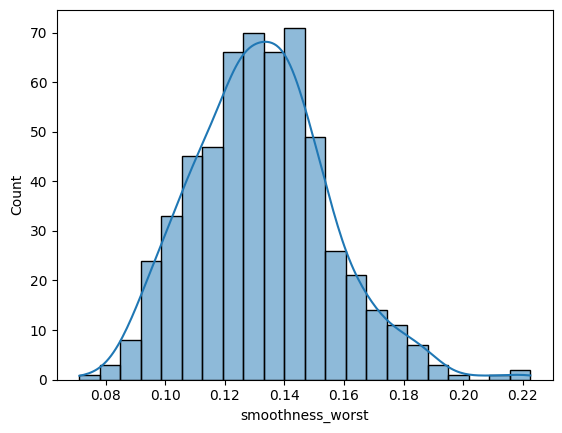

In [62]:
sns.histplot(df["smoothness_worst"], kde=True)

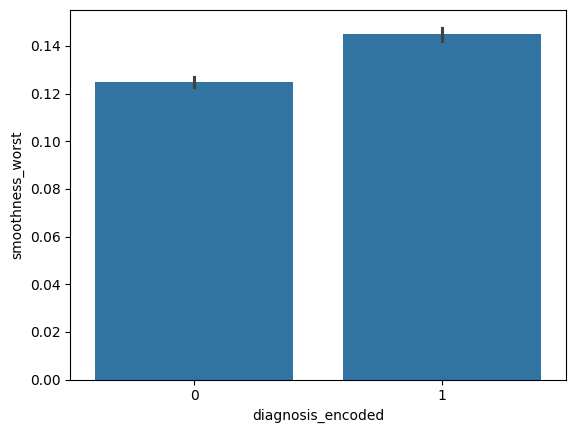

In [63]:
sns.barplot(x="diagnosis_encoded", y="smoothness_worst", data=df)
plt.show()

### 3.6 Compactness

In [64]:
df["compactness_mean"].describe()

count    569.000000
mean       0.104341
std        0.052813
min        0.019380
25%        0.064920
50%        0.092630
75%        0.130400
max        0.345400
Name: compactness_mean, dtype: float64

<Axes: xlabel='compactness_mean', ylabel='Count'>

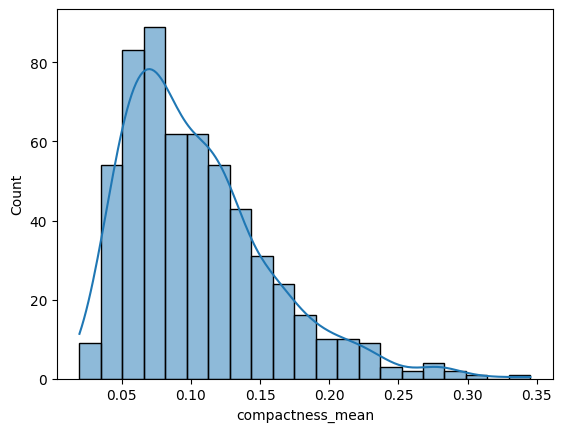

In [65]:
sns.histplot(df["compactness_mean"], kde=True)

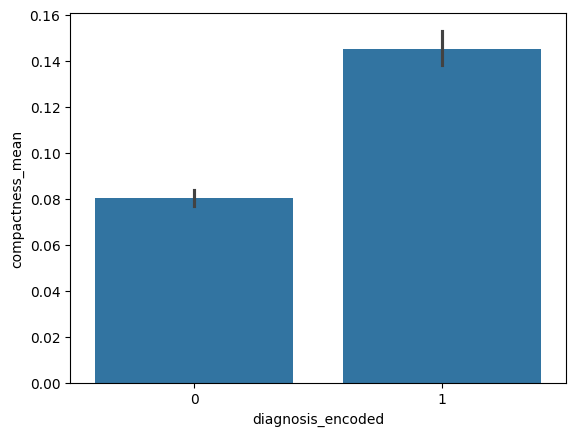

In [66]:
sns.barplot(x="diagnosis_encoded", y="compactness_mean", data=df)
plt.show()

In [67]:
df["compactness_se"].describe()

count    569.000000
mean       0.025478
std        0.017908
min        0.002252
25%        0.013080
50%        0.020450
75%        0.032450
max        0.135400
Name: compactness_se, dtype: float64

<Axes: xlabel='compactness_se', ylabel='Count'>

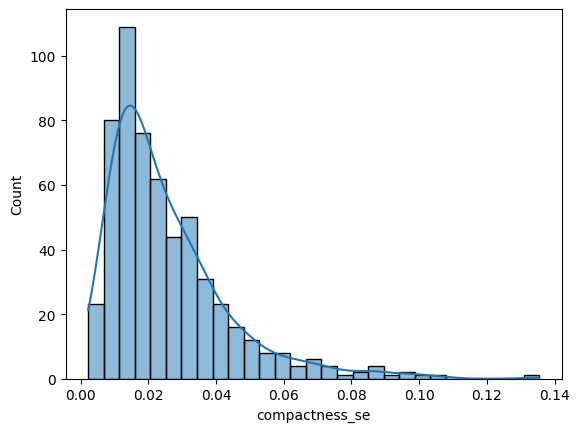

In [68]:
sns.histplot(df["compactness_se"], kde=True)

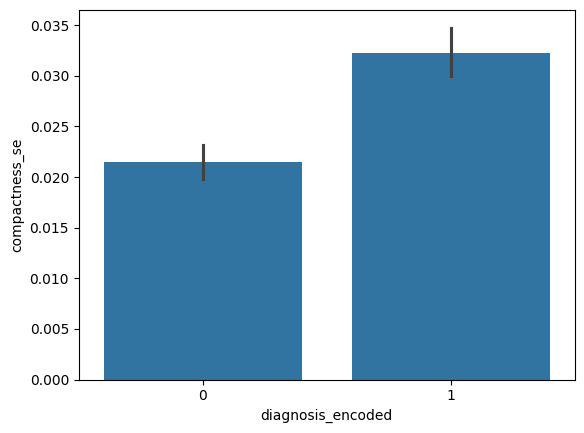

In [69]:
sns.barplot(x="diagnosis_encoded", y="compactness_se", data=df)
plt.show()

In [70]:
df["compactness_worst"].describe()

count    569.000000
mean       0.254265
std        0.157336
min        0.027290
25%        0.147200
50%        0.211900
75%        0.339100
max        1.058000
Name: compactness_worst, dtype: float64

<Axes: xlabel='compactness_worst', ylabel='Count'>

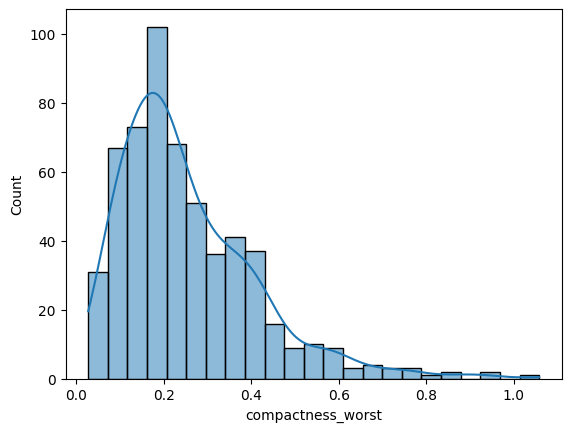

In [71]:
sns.histplot(df["compactness_worst"], kde=True)

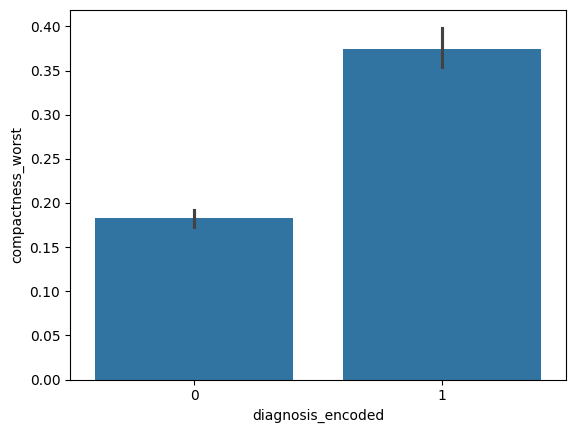

In [72]:
sns.barplot(x="diagnosis_encoded", y="compactness_worst", data=df)
plt.show()

### 3.7 Concavity

In [73]:
df["concavity_mean"].describe()

count    569.000000
mean       0.088799
std        0.079720
min        0.000000
25%        0.029560
50%        0.061540
75%        0.130700
max        0.426800
Name: concavity_mean, dtype: float64

<Axes: xlabel='concavity_mean', ylabel='Count'>

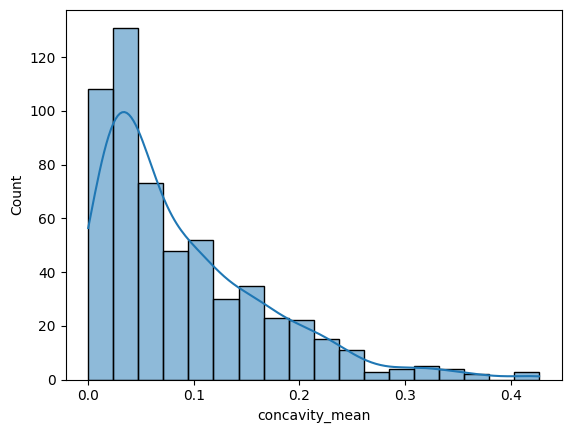

In [74]:
sns.histplot(df["concavity_mean"], kde=True)

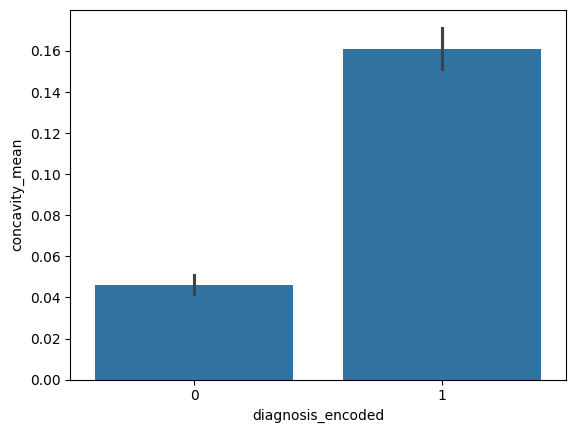

In [75]:
sns.barplot(x="diagnosis_encoded", y="concavity_mean", data=df)
plt.show()

In [76]:
df["concavity_se"].describe()

count    569.000000
mean       0.031894
std        0.030186
min        0.000000
25%        0.015090
50%        0.025890
75%        0.042050
max        0.396000
Name: concavity_se, dtype: float64

<Axes: xlabel='concavity_se', ylabel='Count'>

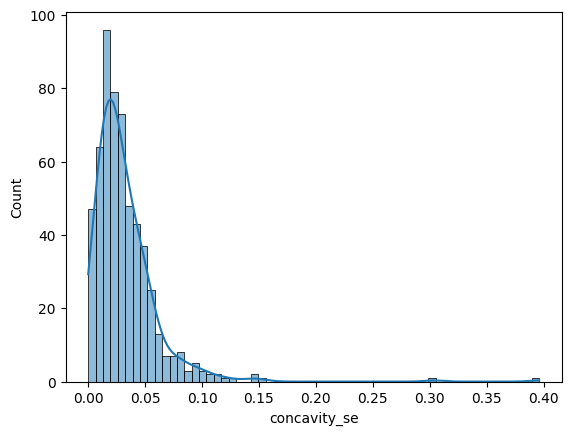

In [77]:
sns.histplot(df["concavity_se"], kde=True)

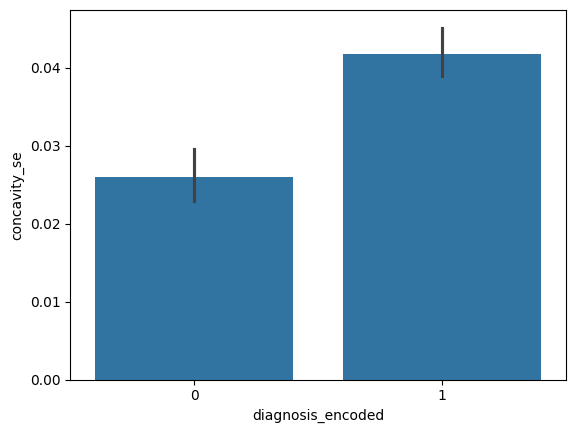

In [78]:
sns.barplot(x="diagnosis_encoded", y="concavity_se", data=df)
plt.show()

In [79]:
df["concavity_worst"].describe()

count    569.000000
mean       0.272188
std        0.208624
min        0.000000
25%        0.114500
50%        0.226700
75%        0.382900
max        1.252000
Name: concavity_worst, dtype: float64

<Axes: xlabel='concavity_worst', ylabel='Count'>

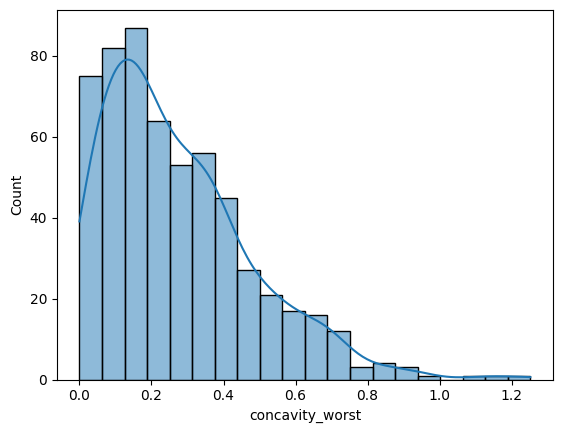

In [80]:
sns.histplot(df["concavity_worst"], kde=True)

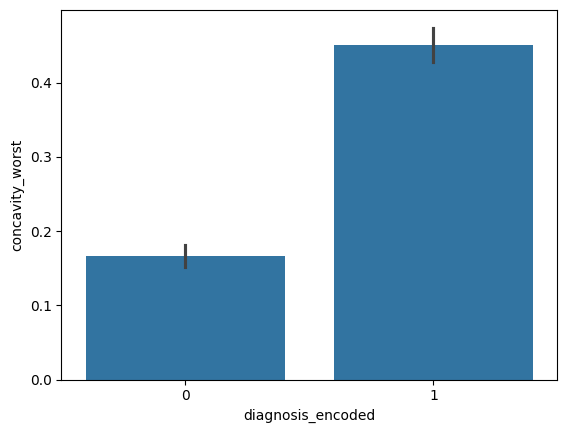

In [81]:
sns.barplot(x="diagnosis_encoded", y="concavity_worst", data=df)
plt.show()

### 3.8 Concave Points

In [82]:
df["concave points_mean"].describe()

count    569.000000
mean       0.048919
std        0.038803
min        0.000000
25%        0.020310
50%        0.033500
75%        0.074000
max        0.201200
Name: concave points_mean, dtype: float64

<Axes: xlabel='concave points_mean', ylabel='Count'>

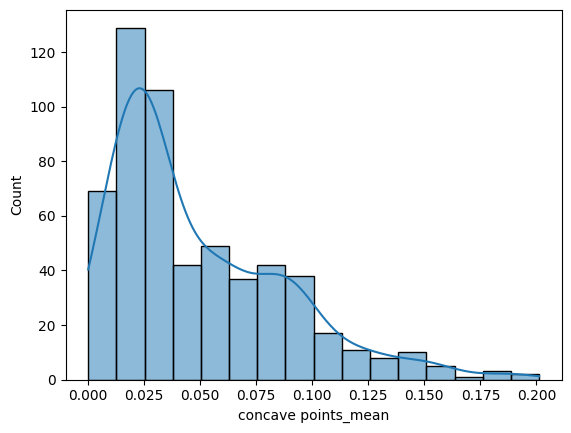

In [83]:
sns.histplot(df["concave points_mean"], kde=True)

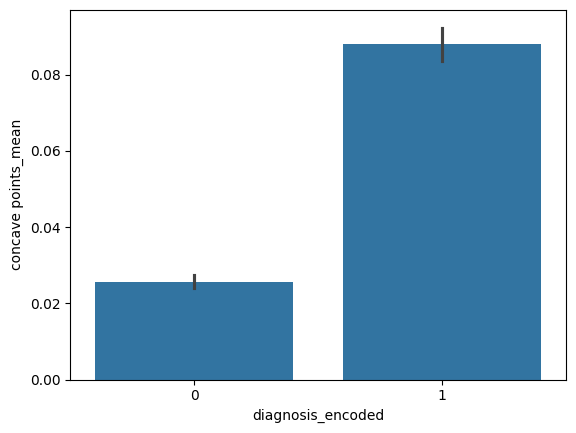

In [84]:
sns.barplot(x="diagnosis_encoded", y="concave points_mean", data=df)
plt.show()

In [85]:
df["concave points_se"].describe()

count    569.000000
mean       0.011796
std        0.006170
min        0.000000
25%        0.007638
50%        0.010930
75%        0.014710
max        0.052790
Name: concave points_se, dtype: float64

<Axes: xlabel='concave points_se', ylabel='Count'>

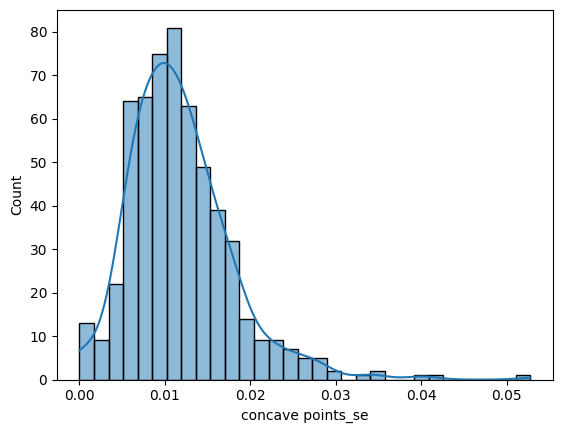

In [86]:
sns.histplot(df["concave points_se"], kde=True)

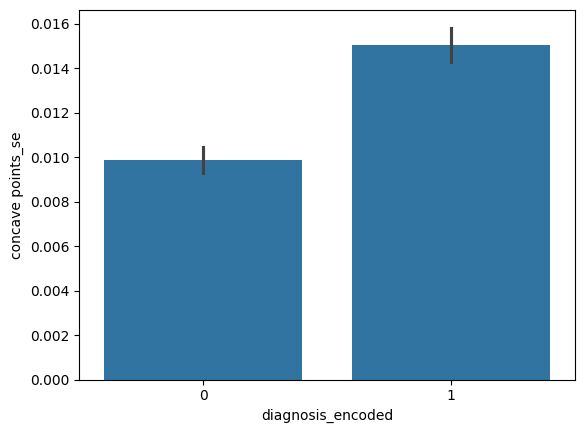

In [87]:
sns.barplot(x="diagnosis_encoded", y="concave points_se", data=df)
plt.show()

In [88]:
df["concave points_worst"].describe()

count    569.000000
mean       0.114606
std        0.065732
min        0.000000
25%        0.064930
50%        0.099930
75%        0.161400
max        0.291000
Name: concave points_worst, dtype: float64

<Axes: xlabel='concave points_worst', ylabel='Count'>

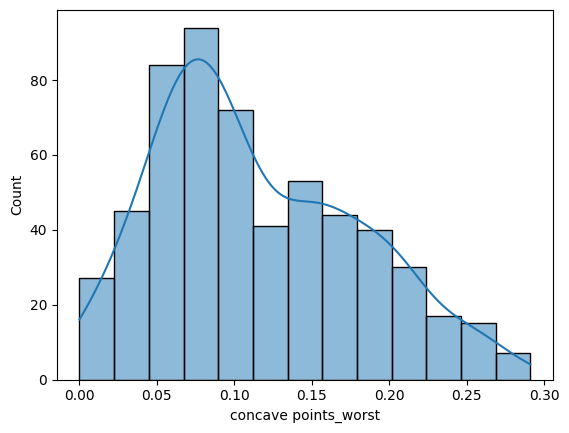

In [89]:
sns.histplot(df["concave points_worst"], kde=True)

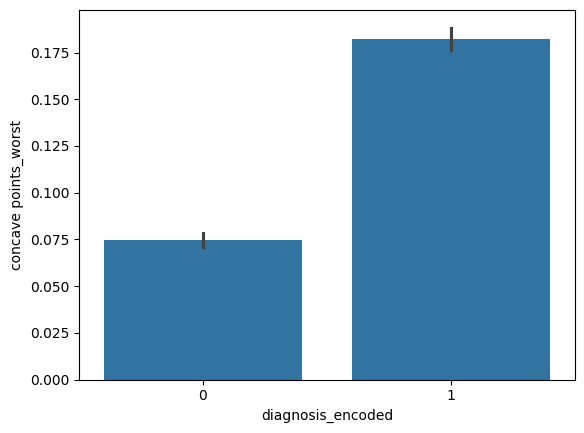

In [90]:
sns.barplot(x="diagnosis_encoded", y="concave points_worst", data=df)
plt.show()

### 3.9 Symmetry

In [91]:
df["symmetry_mean"].describe()

count    569.000000
mean       0.181162
std        0.027414
min        0.106000
25%        0.161900
50%        0.179200
75%        0.195700
max        0.304000
Name: symmetry_mean, dtype: float64

<Axes: xlabel='symmetry_mean', ylabel='Count'>

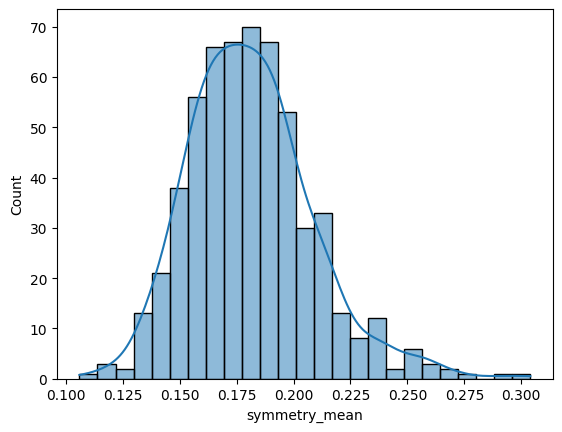

In [92]:
sns.histplot(df["symmetry_mean"], kde=True)

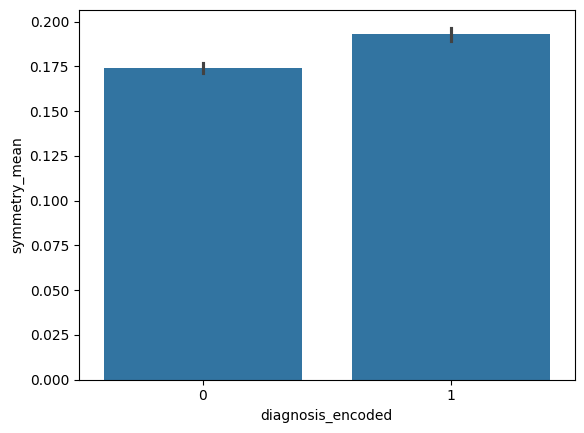

In [93]:
sns.barplot(x="diagnosis_encoded", y="symmetry_mean", data=df)
plt.show()

In [94]:
df["symmetry_se"].describe()

count    569.000000
mean       0.020542
std        0.008266
min        0.007882
25%        0.015160
50%        0.018730
75%        0.023480
max        0.078950
Name: symmetry_se, dtype: float64

<Axes: xlabel='symmetry_se', ylabel='Count'>

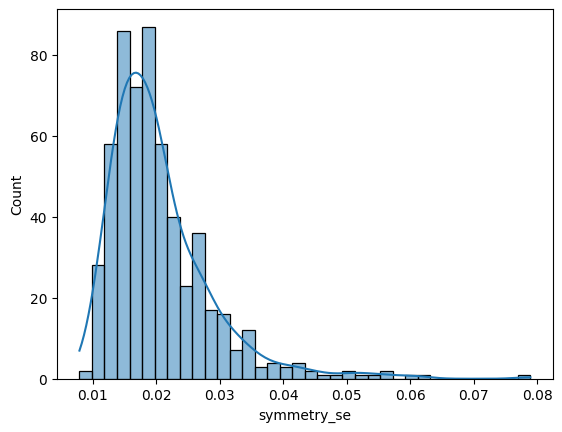

In [95]:
sns.histplot(df["symmetry_se"], kde=True)

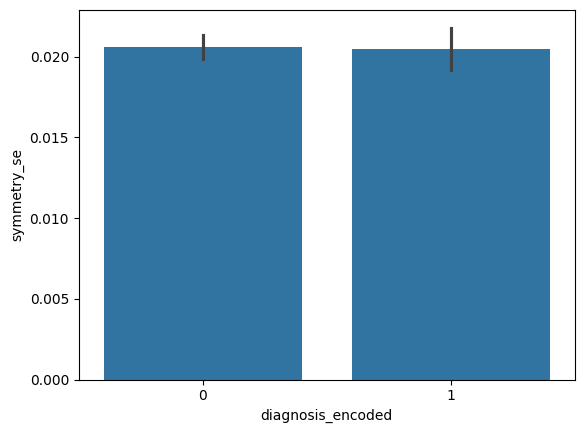

In [96]:
sns.barplot(x="diagnosis_encoded", y="symmetry_se", data=df)
plt.show()

In [97]:
df["symmetry_worst"].describe()

count    569.000000
mean       0.290076
std        0.061867
min        0.156500
25%        0.250400
50%        0.282200
75%        0.317900
max        0.663800
Name: symmetry_worst, dtype: float64

<Axes: xlabel='symmetry_worst', ylabel='Count'>

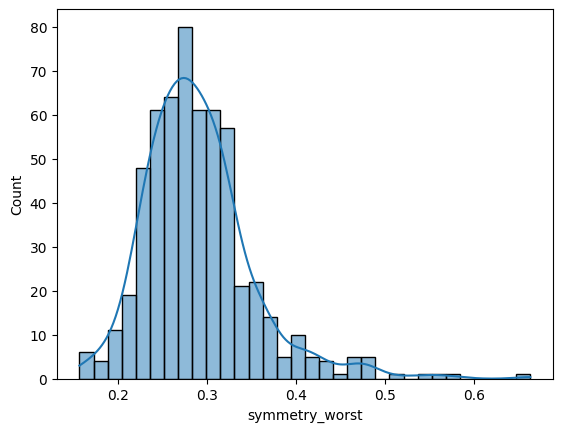

In [98]:
sns.histplot(df["symmetry_worst"], kde=True)

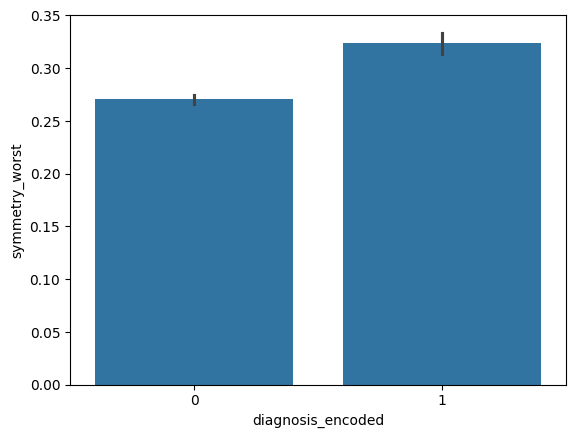

In [99]:
sns.barplot(x="diagnosis_encoded", y="symmetry_worst", data=df)
plt.show()

### 3.10 Fractal Dimension

In [100]:
df["fractal_dimension_mean"].describe()

count    569.000000
mean       0.062798
std        0.007060
min        0.049960
25%        0.057700
50%        0.061540
75%        0.066120
max        0.097440
Name: fractal_dimension_mean, dtype: float64

<Axes: xlabel='fractal_dimension_mean', ylabel='Count'>

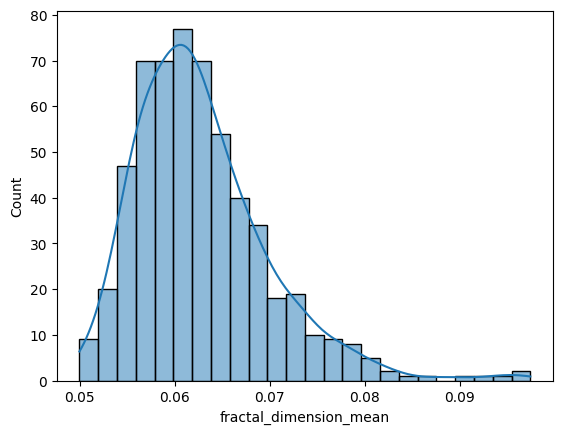

In [101]:
sns.histplot(df["fractal_dimension_mean"], kde=True)

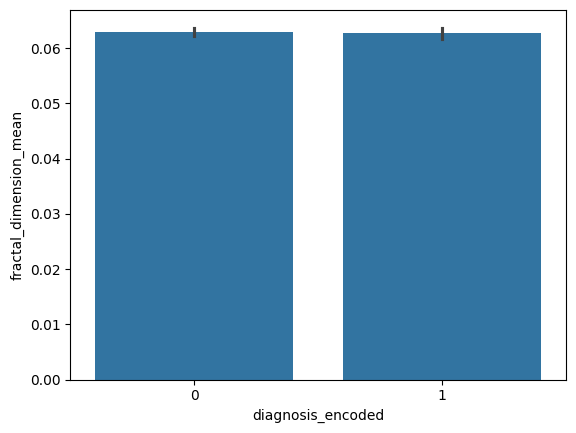

In [102]:
sns.barplot(x="diagnosis_encoded", y="fractal_dimension_mean", data=df)
plt.show()

In [103]:
df["fractal_dimension_se"].describe()

count    569.000000
mean       0.003795
std        0.002646
min        0.000895
25%        0.002248
50%        0.003187
75%        0.004558
max        0.029840
Name: fractal_dimension_se, dtype: float64

<Axes: xlabel='fractal_dimension_se', ylabel='Count'>

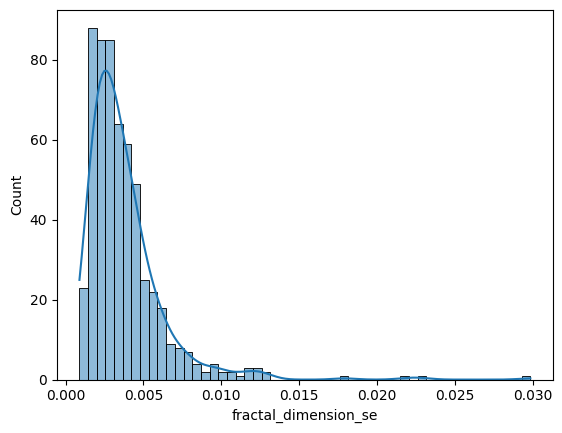

In [104]:
sns.histplot(df["fractal_dimension_se"], kde=True)

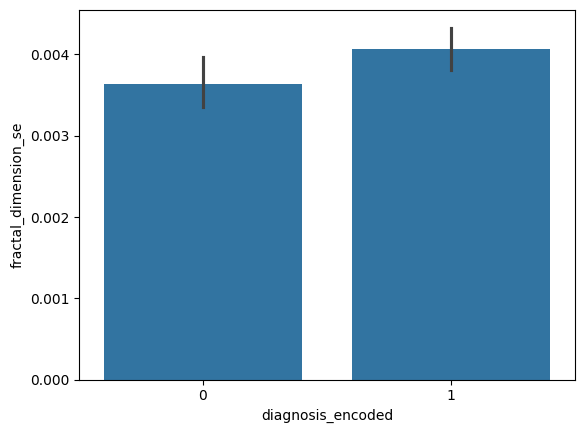

In [105]:
sns.barplot(x="diagnosis_encoded", y="fractal_dimension_se", data=df)
plt.show()

In [106]:
df["fractal_dimension_worst"].describe()

count    569.000000
mean       0.083946
std        0.018061
min        0.055040
25%        0.071460
50%        0.080040
75%        0.092080
max        0.207500
Name: fractal_dimension_worst, dtype: float64

<Axes: xlabel='fractal_dimension_worst', ylabel='Count'>

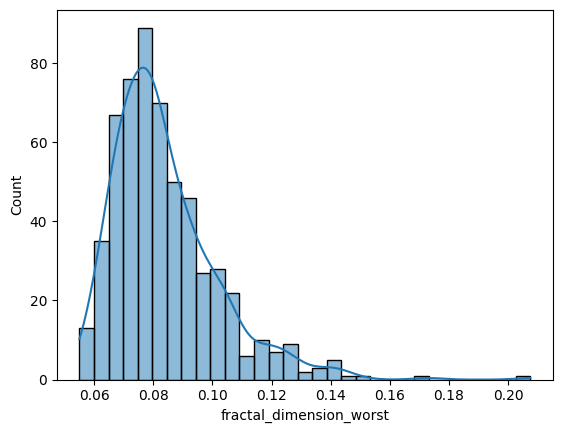

In [107]:
sns.histplot(df["fractal_dimension_worst"], kde=True)

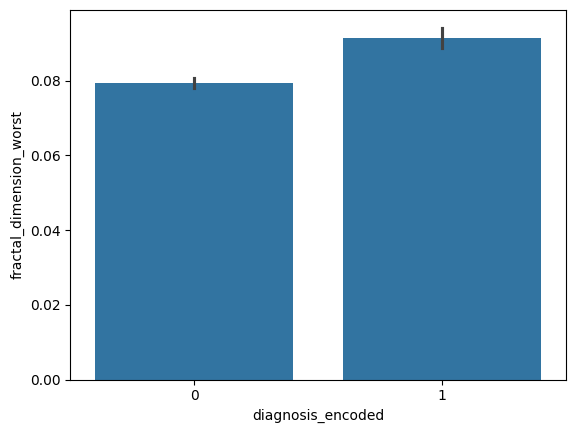

In [108]:
sns.barplot(x="diagnosis_encoded", y="fractal_dimension_worst", data=df)
plt.show()

### Overall EDA Observations

The exploratory analysis shows that several diagnostic features differ noticeably between benign and malignant tumors. Many of the mean and worst-case measurements show higher values for malignant cases, while some standard-error features provide weaker separation.

Several features also show skewed distributions, particularly among the standard-error measurements. These distribution patterns and differences between the target classes provide useful context for the modelling stage.

The feature analysis is exploratory and is used to understand the data rather than to make final feature-selection decisions.

## 4. Feature Correlation Analysis

In [109]:
featured_columns = df.iloc[:, 1:31]
featured_columns

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [110]:
correlation = featured_columns.corr()
correlation

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
radius_mean,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.969539,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066
texture_mean,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.352573,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205
perimeter_mean,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.969476,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019
area_mean,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.962746,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738
smoothness_mean,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.213120,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316
compactness_mean,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.535315,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382
concavity_mean,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.688236,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930
concave points_mean,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.830318,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661
symmetry_mean,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.185728,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413
fractal_dimension_mean,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.253691,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297


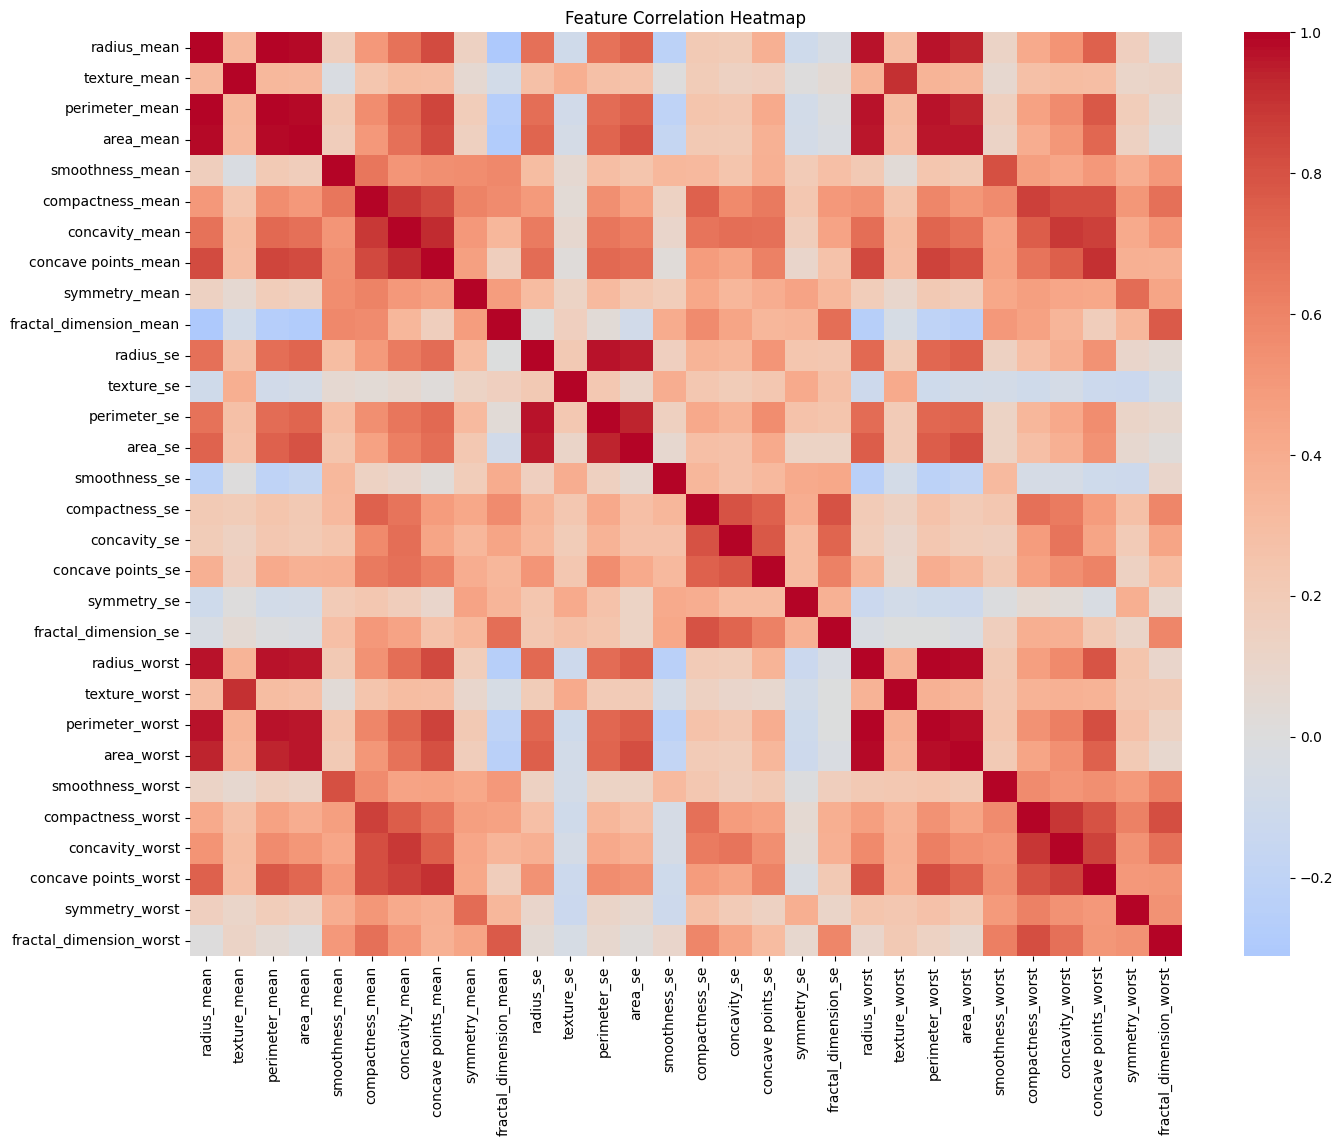

In [111]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [112]:
correlation_with_target = pd.concat(
    [featured_columns, df["diagnosis_encoded"]], 
    axis=1
)

In [113]:
correlation_with_target = correlation_with_target.corr()

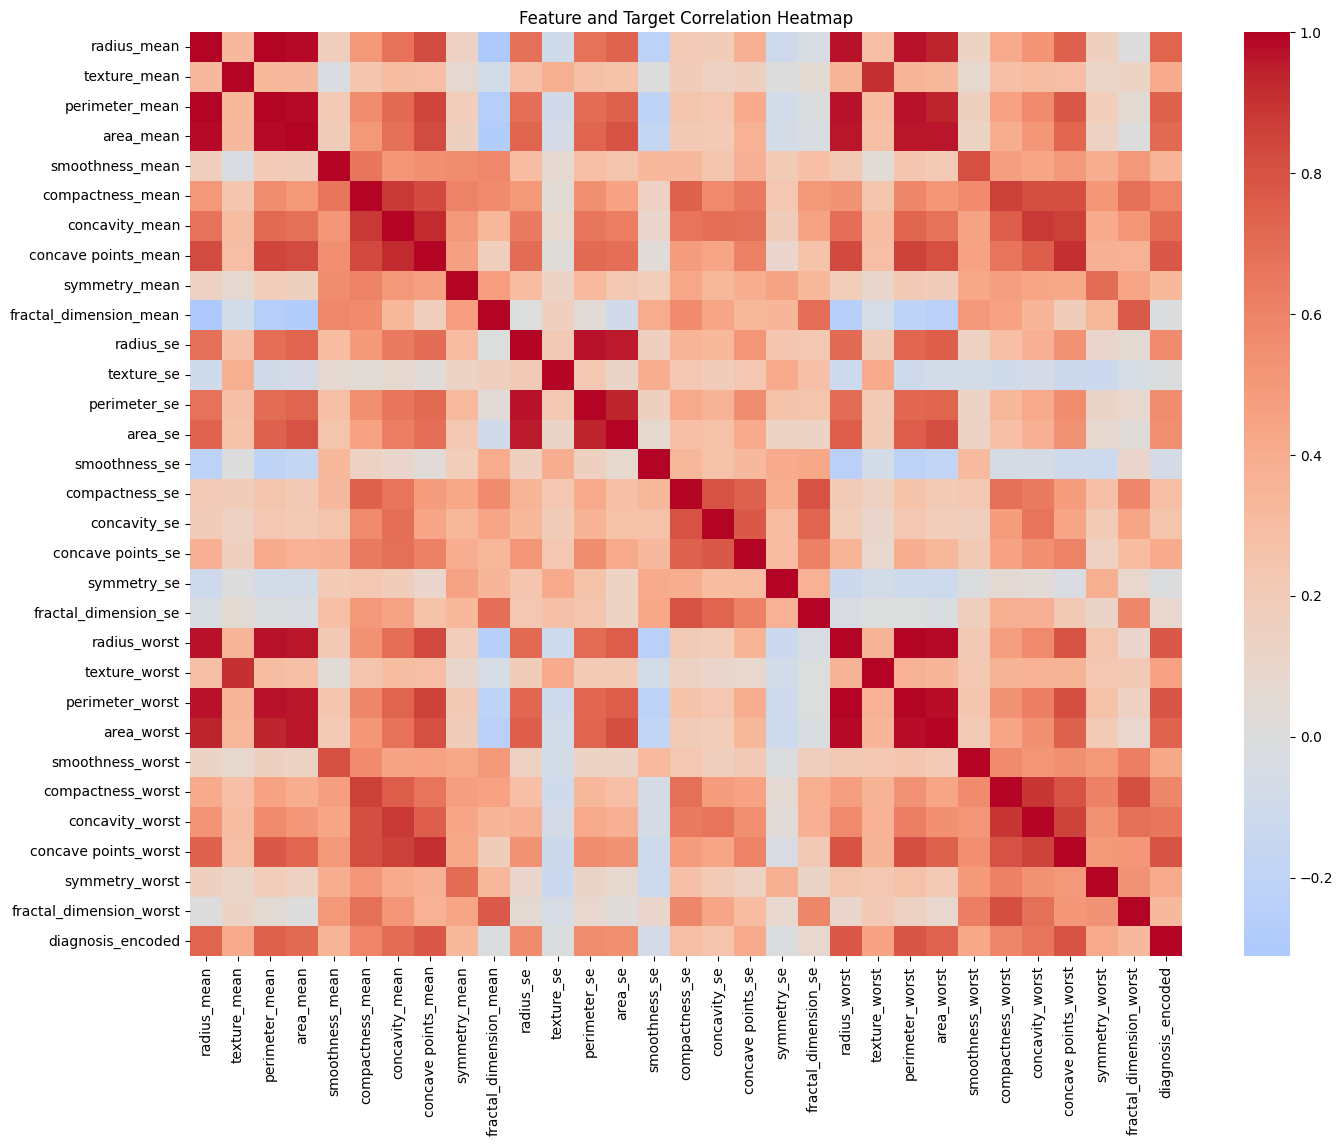

In [114]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_with_target,
    cmap="coolwarm",
    center=0
)

plt.title("Feature and Target Correlation Heatmap")
plt.show()

## 5. Feature and Target Preparation

In [115]:
X = df.iloc[:, 1:31]
y = df.iloc[:, -1]

In [116]:
X.shape

(569, 30)

In [117]:
y.shape

(569,)

## 6. Train-Test Split

In [118]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [119]:
X_train.shape

(455, 30)

In [120]:
X_test.shape

(114, 30)

In [121]:
y_train.value_counts(normalize=True)

diagnosis_encoded
0    0.626374
1    0.373626
Name: proportion, dtype: float64

In [122]:
y_test.value_counts(normalize=True)

diagnosis_encoded
0    0.631579
1    0.368421
Name: proportion, dtype: float64

## 7. Data Preprocessing

In [123]:
scaler = StandardScaler()

In [124]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [125]:
X_train_scaled.shape, X_test_scaled.shape

((455, 30), (114, 30))

## 8. Baseline Model

In [126]:
baseline = DummyClassifier(strategy="most_frequent")

In [127]:
baseline.fit(X_train, y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [128]:
y_pred_baseline = baseline.predict(X_test)

In [129]:
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
print(baseline_accuracy)

0.631578947368421


## 9. Model Training

Model training is performed using three different classification algorithms to compare their performance on the same train-test split.

Logistic Regression is evaluated as a linear baseline, while Decision Tree and Random Forest are included to compare tree-based approaches with different modelling strategies.

### 9.1 Logistic Regression

In [130]:
lr = LogisticRegression()

In [131]:
lr.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [132]:
y_pred_lr = lr.predict(X_test_scaled)

In [133]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print(lr_accuracy)

0.9649122807017544


In [134]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)

[[71  1]
 [ 3 39]]


In [135]:
print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))

Logistic Regression
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [136]:
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
print(y_pred_lr)

[0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


In [137]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

In [138]:
print(fpr)
print(tpr)

[0.         0.         0.         0.01388889 0.01388889 0.13888889
 0.13888889 1.        ]
[0.         0.02380952 0.92857143 0.92857143 0.97619048 0.97619048
 1.         1.        ]


In [139]:
auc_score = roc_auc_score(y_test, y_prob_lr)
print(auc_score)

0.996031746031746


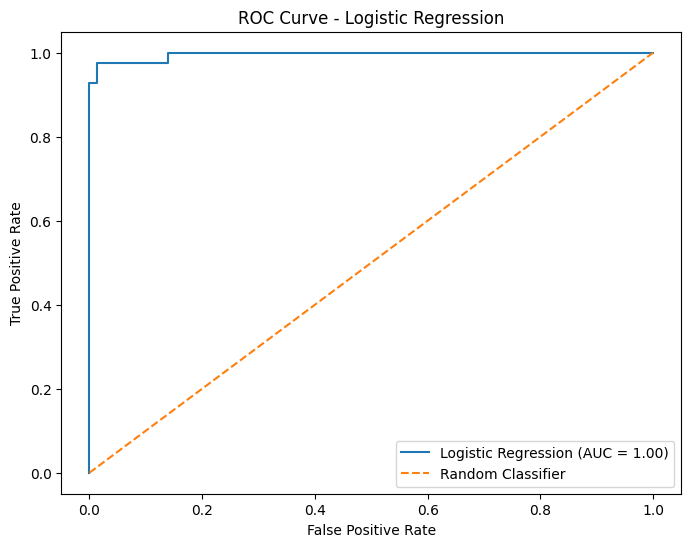

In [140]:
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

### 9.2 Decision Tree

In [141]:
dt = DecisionTreeClassifier(random_state=42)

In [142]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [143]:
y_pred_dt = dt.predict(X_test)

In [144]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(dt_accuracy)

0.9298245614035088


In [145]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[68  4]
 [ 4 38]]


In [146]:
print("Decision Tree")
print(classification_report(y_test, y_pred_dt))

Decision Tree
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        72
           1       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



### 9.3 Random Forest

In [147]:
rf = RandomForestClassifier(random_state=42)

In [148]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [149]:
y_pred_rf = rf.predict(X_test)

In [150]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(rf_accuracy)

0.9736842105263158


In [151]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[72  0]
 [ 3 39]]


In [152]:
print("Random Forest")
print(classification_report(y_test, y_pred_rf))

Random Forest
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [153]:
y_prob_rf = rf.predict_proba(X_test)[:, 1]
print(y_pred_rf)

[0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]


In [154]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

In [155]:
print(fpr)
print(tpr)

[0.         0.         0.         0.         0.         0.
 0.04166667 0.04166667 0.08333333 0.08333333 0.09722222 0.125
 0.15277778 0.19444444 0.20833333 0.23611111 0.27777778 0.33333333
 0.375      0.52777778 1.        ]
[0.         0.42857143 0.52380952 0.64285714 0.71428571 0.92857143
 0.92857143 0.95238095 0.95238095 0.97619048 0.97619048 0.97619048
 0.97619048 1.         1.         1.         1.         1.
 1.         1.         1.        ]


In [156]:
auc_score = roc_auc_score(y_test, y_prob_rf)
print(auc_score)

0.9928902116402116


## 10. Model Evaluation

### 10.1 Cross-Validation

Cross-validation is used to evaluate how consistently each model performs across different subsets of the training data.

A 5-fold cross-validation is performed using accuracy as the evaluation metric. The mean score represents the average performance across the folds, while the standard deviation indicates how much the performance varies between folds.

In [157]:
lr_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression())
])

cv_scores_lr = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

cv_scores_lr

array([0.96703297, 0.98901099, 0.95604396, 0.97802198, 0.96703297])

In [158]:
print(cv_scores_lr.mean())
print(cv_scores_lr.std())

0.9714285714285715
0.011206636293610512


In [159]:
cv_scores_dt = cross_val_score(
    dt,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

cv_scores_dt

array([0.96703297, 0.95604396, 0.91208791, 0.93406593, 0.89010989])

In [160]:
print(cv_scores_dt.mean())
print(cv_scores_dt.std())

0.9318681318681318
0.0281456010436609


In [161]:
cv_scores_rf = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

cv_scores_rf

array([1.        , 0.98901099, 0.93406593, 0.97802198, 0.91208791])

In [162]:
print(cv_scores_rf.mean())
print(cv_scores_rf.std())

0.9626373626373628
0.033763278012609275


### Cross-Validation Observations

Logistic Regression achieved the highest mean cross-validation accuracy of **97.14%** and the lowest standard deviation of **1.12 percentage points**, indicating strong and consistent performance across the five folds.

Random Forest achieved a mean accuracy of **95.82%**, while Decision Tree achieved **91.87%**. Based on the cross-validation results, Logistic Regression provides the strongest and most consistent performance among the evaluated models.

## 11. Final Model Selection

Logistic Regression was selected as the final model based on its performance across the evaluation results. It achieved the highest mean cross-validation accuracy among the evaluated models, along with the lowest cross-validation standard deviation, while also matching the Random Forest on test accuracy.

A final pipeline combining `StandardScaler` and Logistic Regression is used so that preprocessing and prediction remain part of the same reproducible workflow.

In [163]:
pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression())
])

### 11.1 Final Model Evaluation

Model evaluation is used to assess how well each trained classifier performs on the test set.

Accuracy provides an overall measure of correct predictions, while the confusion matrix and classification report provide a more detailed view of errors and class-wise performance. ROC-AUC is also considered to evaluate the model's ability to distinguish between the two classes across different classification thresholds.

In [164]:
pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [165]:
y_pred_pipeline = pipeline.predict(X_test)

In [166]:
accuracy_pipeline = accuracy_score(y_test, y_pred_pipeline)
accuracy_pipeline

0.9649122807017544

In [167]:
cm_pipeline = confusion_matrix(y_test, y_pred_pipeline)
print(cm_pipeline)

[[71  1]
 [ 3 39]]


In [168]:
print("LR Pipeline")
print(classification_report(y_test, y_pred_pipeline))

LR Pipeline
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



The final pipeline achieved **96.49% accuracy** on the test set, with strong performance across both classes. It correctly identified 39 of 42 malignant cases, while 3 malignant cases were misclassified as benign.

The result is consistent with the earlier Logistic Regression evaluation, confirming that combining preprocessing and the classifier into a single pipeline preserves the model's predictive performance.

## 12. Conclusion

This project followed an end-to-end binary classification workflow, from dataset understanding and exploratory analysis to preprocessing, model comparison, cross-validation, final model selection, and evaluation.

Among the evaluated models, Logistic Regression was selected as the final model based on its cross-validation performance and test-set results. The final pipeline combines feature scaling with Logistic Regression to keep preprocessing and prediction together in a reproducible workflow.

The final model achieved **96.49% test accuracy**, with a **0.996 ROC-AUC**, while correctly identifying most benign and malignant cases.

## 13. Model Serialization

The final Logistic Regression pipeline is serialized so that the complete preprocessing and prediction workflow can be saved and reused without retraining the model.

In [169]:
import joblib 

In [170]:
joblib.dump(pipeline, "../models/breast_cancer_logistic_regression_pipeline.joblib")

['../models/breast_cancer_logistic_regression_pipeline.joblib']

In [171]:
loaded_pipeline = joblib.load("../models/breast_cancer_logistic_regression_pipeline.joblib")

y_pred_loaded = loaded_pipeline.predict(X_test)

accuracy_loaded = accuracy_score(y_test, y_pred_loaded)

print("Loaded pipeline accuracy:", accuracy_loaded)

Loaded pipeline accuracy: 0.9649122807017544


The serialized pipeline was successfully loaded and evaluated on the test set. It produced the same **96.49% accuracy** as the original pipeline, confirming that the saved preprocessing and model workflow can be reused without retraining.